# San Francisco Neighborhood Accessibility

## Setup
This notebook uses pandas, GeoPandas, Matplotlib, Requests, and OSMnx.

Before running the notebook, activate the project's `.venv` environment
and install the packages listed in `requirements.txt`.
Select that environment as the notebook's Python kernel.

In [3]:
# Confirm which Python environment is running this notebook.
import sys
from pathlib import Path

print("Python executable:", sys.executable)
print("Working folder:", Path.cwd())

Python executable: /Users/prabhavpagadala/Documents/CyPlan101/Project/cyplan-101-project/.venv/bin/python
Working folder: /Users/prabhavpagadala/Documents/CyPlan101/Project/cyplan-101-project


In [4]:
# Load the packages used for data analysis, maps, and Census requests.
from pathlib import Path
import os

import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import requests

# Display maps and charts directly below notebook cells.
%matplotlib inline

In [5]:
# Use a relative path so the project can run on another computer.
neighborhood_file = Path("data/analysis_neighborhoods.geojson")

# Check that the boundary file is available before loading it.
if not neighborhood_file.is_file():
    raise FileNotFoundError(
        f"Neighborhood boundary file not found: {neighborhood_file}"
    )

# Load San Francisco's analysis neighborhood boundaries.
neighborhoods = gpd.read_file(neighborhood_file)

print("Number of neighborhoods:", len(neighborhoods))
print("Original CRS:", neighborhoods.crs)
display(neighborhoods[["nhood", "geometry"]].head())

Number of neighborhoods: 41
Original CRS: EPSG:4326


,nhood,geometry
0,Western Addition,"MULTIPOLYGON (((-122.42144 37.78557, -122.4213..."
1,West of Twin Peaks,"MULTIPOLYGON (((-122.46104 37.75096, -122.4605..."
2,Visitacion Valley,"MULTIPOLYGON (((-122.40385 37.71883, -122.4035..."
3,Twin Peaks,"MULTIPOLYGON (((-122.44695 37.75655, -122.4459..."
4,South of Market,"MULTIPOLYGON (((-122.40371 37.78404, -122.4027..."


## Neighborhood boundaries

We use San Francisco’s 41 analysis neighborhoods as our study areas.
Before spatial analysis, we check neighborhood names and geometries
for missing values, duplicates, and invalid shapes.

In [6]:
# Check the boundaries before using them in spatial calculations.
neighborhood_checks = pd.Series({
    "Total neighborhoods": len(neighborhoods),
    "Missing neighborhood names": neighborhoods["nhood"].isna().sum(),
    "Duplicate neighborhood names": (
        neighborhoods["nhood"].duplicated().sum()
    ),
    "Missing geometries": neighborhoods.geometry.isna().sum(),
    "Empty geometries": neighborhoods.geometry.is_empty.sum(),
    "Invalid nonmissing geometries": (
        neighborhoods.geometry.notna()
        & ~neighborhoods.geometry.is_valid
    ).sum()
})

display(neighborhood_checks)

Total neighborhoods              41
Missing neighborhood names        0
Duplicate neighborhood names      0
Missing geometries                0
Empty geometries                  0
Invalid nonmissing geometries     0
dtype: int64

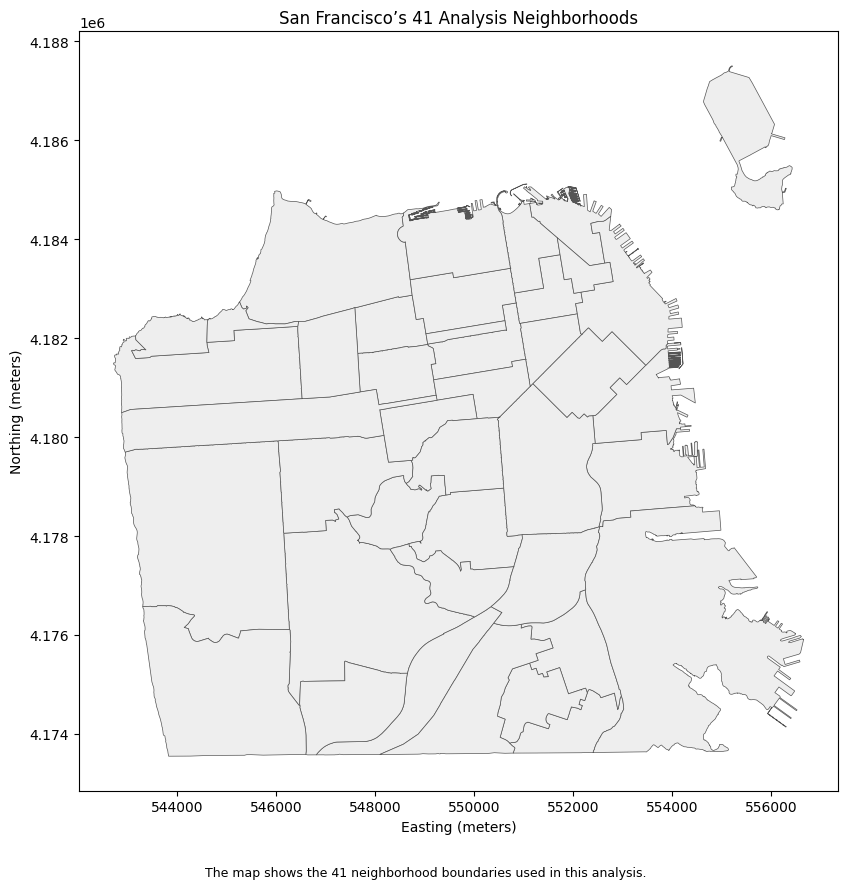

Projected CRS: EPSG:26910


In [16]:
# Convert longitude/latitude coordinates to a projected CRS in meters.
neighborhoods_projected = neighborhoods.to_crs(epsg=26910)

# Draw the study area's neighborhood boundaries.
fig, ax = plt.subplots(figsize=(9, 9))

neighborhoods_projected.plot(
    ax=ax,
    color="#eeeeee",
    edgecolor="#555555",
    linewidth=0.5
)

ax.set_title("San Francisco’s 41 Analysis Neighborhoods")
ax.set_xlabel("Easting (meters)")
ax.set_ylabel("Northing (meters)")

fig.text(
    0.5, 0.02,
    "The map shows the 41 neighborhood boundaries used in this analysis.",
    ha="center",
    fontsize=9
)

plt.tight_layout(rect=[0, 0.05, 1, 1])
plt.show()

print("Projected CRS:", neighborhoods_projected.crs)

## Census income and household data

We use the 2024 ACS five-year estimates, covering 2020–2024, for
San Francisco census tracts. These include median household income,
total households, and their margins of error. We inspect and clean
these values before attaching them to tract boundaries.

In [11]:
# Reuse the original Census response saved during the earlier analysis.
raw_dir = Path("data/raw")
acs_raw_file = raw_dir / "acs_2024_sf_tracts_raw.csv"

# Read as text to preserve leading zeros in Census geographic codes.
income_raw = pd.read_csv(acs_raw_file, dtype=str)

print("Census tract records loaded:", len(income_raw))
display(income_raw.head())

Census tract records loaded: 244


,NAME,B19013_001E,B19013_001M,B11001_001E,B11001_001M,state,county,tract
0,Census Tract 101.01; San Francisco County; Cal...,89022,40627,1216,150,06,075,010101
1,Census Tract 101.02; San Francisco County; Cal...,102826,55857,930,211,06,075,010102
2,Census Tract 102.01; San Francisco County; Cal...,156017,4484,1399,179,06,075,010201
3,Census Tract 102.02; San Francisco County; Cal...,176958,57906,1099,174,06,075,010202
4,Census Tract 103; San Francisco County; Califo...,158144,24737,2060,340,06,075,010300


In [8]:
# Give the Census variables readable names.
income = income_raw.rename(columns={
    "B19013_001E": "median_income",
    "B19013_001M": "income_moe",
    "B11001_001E": "households",
    "B11001_001M": "households_moe"
}).copy()

# Convert estimates and margins of error from text to numbers.
numeric_columns = [
    "median_income",
    "income_moe",
    "households",
    "households_moe"
]

for column in numeric_columns:
    income[column] = pd.to_numeric(income[column], errors="coerce")

# Combine geographic codes into each tract's unique Census identifier.
income["GEOID"] = (
    income["state"] + income["county"] + income["tract"]
)

# Count potential data issues before replacing or removing anything.
income_checks = pd.DataFrame({
    "Missing values": income[numeric_columns].isna().sum(),
    "Negative values": income[numeric_columns].lt(0).sum(),
    "Zero values": income[numeric_columns].eq(0).sum()
})

display(income_checks)

print("Total tract records:", len(income))
print("Duplicate GEOIDs:", income["GEOID"].duplicated().sum())
print("Rows removed so far: 0")

,Missing values,Negative values,Zero values
median_income,0,10,0
income_moe,0,20,0
households,0,0,4
households_moe,0,0,0


Total tract records: 244
Duplicate GEOIDs: 0
Rows removed so far: 0


In [9]:
# Keep the original table unchanged for comparison.
income_clean = income.copy()

# Flag medians in an open-ended income interval BEFORE replacing codes.
# Their reported income values represent bounds rather than exact medians.
income_clean["income_open_ended"] = (
    income_clean["income_moe"].eq(-333333333)
)

# Census codes representing missing values or special conditions.
special_codes = [
    -666666666,
    -999999999,
    -888888888,
    -222222222,
    -333333333,
    -555555555
]

# Replace special codes and document how many values were affected.
cleaning_records = []

for column in numeric_columns:
    special_mask = income_clean[column].isin(special_codes)

    cleaning_records.append({
        "column": column,
        "special_codes_replaced": int(special_mask.sum())
    })

    income_clean.loc[special_mask, column] = float("nan")

acs_cleaning_log = pd.DataFrame(cleaning_records)

# Stop if an unexpected negative value remains.
assert not income_clean[numeric_columns].lt(0).any().any(), (
    "Unexpected negative values remain. Inspect them before continuing."
)

# Income weighting requires an income estimate and positive households.
# A missing margin of error alone does not exclude an income estimate.
income_clean["eligible_for_income_weighting"] = (
    income_clean["median_income"].notna()
    & income_clean["households"].notna()
    & income_clean["households"].gt(0)
)

display(acs_cleaning_log)

print("Tracts retained:", len(income_clean))
print(
    "Eligible for income weighting:",
    income_clean["eligible_for_income_weighting"].sum()
)
print(
    "Open-ended income estimates:",
    income_clean["income_open_ended"].sum()
)

,column,special_codes_replaced
0,median_income,10
1,income_moe,20
2,households,0
3,households_moe,0


Tracts retained: 244
Eligible for income weighting: 234
Open-ended income estimates: 10


In [12]:
def download_if_missing(url, destination):
    """Download a source file only when no local copy exists."""
    destination = Path(destination)
    destination.parent.mkdir(parents=True, exist_ok=True)

    if destination.is_file():
        print("Using existing file:", destination)
    else:
        print("Downloading:", destination)
        response = requests.get(url, timeout=120)
        response.raise_for_status()
        destination.write_bytes(response.content)

    return destination


# California's 2024 Census tract boundaries.
tract_url = (
    "https://www2.census.gov/geo/tiger/"
    "TIGER2024/TRACT/tl_2024_06_tract.zip"
)

tract_file = download_if_missing(
    tract_url,
    raw_dir / "ca_census_tracts.zip"
)

# Read the statewide boundaries.
tracts_ca = gpd.read_file(tract_file)

# Keep only San Francisco County: California 06, county 075.
sf_mask = (
    tracts_ca["STATEFP"].eq("06")
    & tracts_ca["COUNTYFP"].eq("075")
)
tracts = tracts_ca.loc[sf_mask].copy()

# Document the geographic filtering and check tract identifiers.
print("California tract boundaries:", len(tracts_ca))
print("Outside San Francisco, filtered out:", (~sf_mask).sum())
print("San Francisco tract boundaries retained:", len(tracts))
print("Duplicate SF GEOIDs:", tracts["GEOID"].duplicated().sum())
print("Original tract CRS:", tracts.crs)

Using existing file: data/raw/ca_census_tracts.zip
California tract boundaries: 9129
Outside San Francisco, filtered out: 8885
San Francisco tract boundaries retained: 244
Duplicate SF GEOIDs: 0
Original tract CRS: EPSG:4269


In [13]:
# Select the Census fields needed for the analysis.
income_columns = [
    "GEOID",
    "median_income",
    "income_moe",
    "households",
    "households_moe",
    "income_open_ended",
    "eligible_for_income_weighting"
]

# Attach Census statistics to tract polygons using their shared ID.
# one_to_one prevents duplicate IDs from multiplying records.
# The indicator records whether each boundary found a Census match.
tracts_income = tracts.merge(
    income_clean[income_columns],
    on="GEOID",
    how="left",
    validate="one_to_one",
    indicator=True
)

# Check matching and geometry before spatial calculations.
tract_checks = pd.Series({
    "Tract boundaries retained": len(tracts_income),
    "Boundaries matched to Census data": (
        tracts_income["_merge"] == "both"
    ).sum(),
    "Boundaries without a Census match": (
        tracts_income["_merge"] == "left_only"
    ).sum(),
    "Census records without a boundary": (
        ~income_clean["GEOID"].isin(tracts["GEOID"])
    ).sum(),
    "Missing geometries": tracts_income.geometry.isna().sum(),
    "Empty geometries": tracts_income.geometry.is_empty.sum(),
    "Invalid nonmissing geometries": (
        tracts_income.geometry.notna()
        & ~tracts_income.geometry.is_valid
    ).sum()
})

display(tract_checks)

Tract boundaries retained            244
Boundaries matched to Census data    244
Boundaries without a Census match      0
Census records without a boundary      0
Missing geometries                     0
Empty geometries                       0
Invalid nonmissing geometries          0
dtype: int64

## Estimating neighborhood income

We intersect Census tracts with neighborhood boundaries to estimate how
tract households are distributed among neighborhoods. We first inspect
area coverage and allocation gaps before calculating household-weighted
averages of tract median incomes. These are approximate neighborhood
income measures, not official neighborhood medians.

In [17]:
# Project tract boundaries into the same meter-based CRS as neighborhoods.
tracts_projected = (
    tracts_income.drop(columns="_merge")
    .to_crs(epsg=26910)
)

# Measure each tract's full polygon area.
# This includes any water within the tract boundary, not just land.
tracts_projected["tract_area_m2"] = (
    tracts_projected.geometry.area
)

# Split tracts wherever they intersect neighborhood boundaries.
# Keep the Census fields needed for household allocation and quality checks.
overlaps = gpd.overlay(
    neighborhoods_projected[["nhood", "geometry"]],
    tracts_projected[
        income_columns + ["tract_area_m2", "geometry"]
    ],
    how="intersection",
    keep_geom_type=True
)

# Measure each neighborhood–tract intersection in square meters.
overlaps["overlap_area_m2"] = overlaps.geometry.area

print("Neighborhood–tract overlap pieces:", len(overlaps))
print("Neighborhoods represented:", overlaps["nhood"].nunique())
print("Tracts represented:", overlaps["GEOID"].nunique())
print(
    "Pieces with zero or negative area:",
    overlaps["overlap_area_m2"].le(0).sum()
)

display(
    overlaps[
        ["nhood", "GEOID", "median_income", "households",
         "tract_area_m2", "overlap_area_m2"]
    ].head()
)

Neighborhood–tract overlap pieces: 630
Neighborhoods represented: 41
Tracts represented: 242
Pieces with zero or negative area: 0


,nhood,GEOID,median_income,households,tract_area_m2,overlap_area_m2
0,Western Addition,06075012202,57897.0,1374.0,94614.688719,1905.580193
1,Western Addition,06075013102,250001.0,1482.0,237711.993608,2.979060
2,Western Addition,06075015801,121563.0,1527.0,343679.470065,343295.573861
3,Western Addition,06075015100,159921.0,1566.0,171870.833702,171868.655030
4,Western Addition,06075015900,83866.0,2081.0,295359.785565,294896.646992


In [18]:
# Sum the neighborhood-covered area within each tract.
covered_area_by_tract = (
    overlaps.groupby("GEOID")["overlap_area_m2"].sum()
)

# Keep all tracts in this check, including those without overlaps.
tract_coverage = tracts_projected[
    ["GEOID", "NAME", "households", "median_income", "tract_area_m2"]
].copy()

tract_coverage["covered_area_m2"] = (
    tract_coverage["GEOID"]
    .map(covered_area_by_tract)
    .fillna(0)
)

# Calculate the fraction of each tract covered by neighborhoods.
tract_coverage["covered_share"] = (
    tract_coverage["covered_area_m2"]
    / tract_coverage["tract_area_m2"]
)

no_overlap = tract_coverage["covered_area_m2"].eq(0)

# Allow a small tolerance for numerical rounding.
over_covered = tract_coverage["covered_share"].gt(1 + 1e-6)

print("Tracts without neighborhood overlaps:", no_overlap.sum())
print("Tracts with coverage above 100%:", over_covered.sum())

print("\nTracts without neighborhood overlaps:")
display(
    tract_coverage.loc[
        no_overlap,
        ["GEOID", "NAME", "households", "median_income", "covered_share"]
    ]
)

print("\nCoverage-share summary across all tracts:")
display(tract_coverage["covered_share"].describe())

Tracts without neighborhood overlaps: 2
Tracts with coverage above 100%: 0

Tracts without neighborhood overlaps:


,GEOID,NAME,households,median_income,covered_share
31,06075980401,9804.01,0.0,NaN,0.0
195,06075990100,9901,0.0,NaN,0.0



Coverage-share summary across all tracts:


count    244.000000
mean       0.951586
std        0.164954
min        0.000000
25%        1.000000
50%        1.000000
75%        1.000000
max        1.000000
Name: covered_share, dtype: float64

In [19]:
# Calculate each intersection's share of its original tract area.
overlaps["tract_area_share"] = (
    overlaps["overlap_area_m2"]
    / overlaps["tract_area_m2"]
)

# Allocate tract households using that area share.
overlaps["estimated_households"] = (
    overlaps["households"]
    * overlaps["tract_area_share"]
)

# Compare allocated households with the original Census total.
source_households = tracts_projected["households"].sum()
allocated_households = overlaps["estimated_households"].sum()

# Count allocated households associated with usable income estimates.
allocated_with_income = overlaps.loc[
    overlaps["eligible_for_income_weighting"],
    "estimated_households"
].sum()

print(f"Original SF household estimate: {source_households:,.0f}")
print(
    "Households allocated to neighborhoods:",
    f"{allocated_households:,.1f}"
)
print(
    "Household allocation coverage:",
    f"{100 * allocated_households / source_households:.2f}%"
)
print(
    "Share of allocated households with usable income:",
    f"{100 * allocated_with_income / allocated_households:.2f}%"
)

display(
    overlaps[
        ["nhood", "GEOID", "households",
         "tract_area_share", "estimated_households"]
    ].head()
)

Original SF household estimate: 363,970
Households allocated to neighborhoods: 351,875.0
Household allocation coverage: 96.68%
Share of allocated households with usable income: 98.26%


,nhood,GEOID,households,tract_area_share,estimated_households
0,Western Addition,06075012202,1374.0,0.020140,27.672946
1,Western Addition,06075013102,1482.0,0.000013,0.018573
2,Western Addition,06075015801,1527.0,0.998883,1525.294313
3,Western Addition,06075015100,1566.0,0.999987,1565.980149
4,Western Addition,06075015900,2081.0,0.998432,2077.736890


In [20]:
# Sum the households allocated from each tract to neighborhoods.
allocated_by_tract = (
    overlaps.groupby("GEOID")["estimated_households"].sum()
)

# Attach those totals to the coverage table, retaining all 244 tracts.
tract_coverage["allocated_households"] = (
    tract_coverage["GEOID"]
    .map(allocated_by_tract)
    .fillna(0)
)

# Measure the difference from each tract's original household estimate.
tract_coverage["unallocated_households"] = (
    tract_coverage["households"]
    - tract_coverage["allocated_households"]
)

# Identify the ten tracts contributing the largest allocation gaps.
largest_gaps = (
    tract_coverage.sort_values(
        "unallocated_households",
        ascending=False
    )
    .head(10)
    .copy()
)

display(
    largest_gaps[
        ["GEOID", "NAME", "households", "covered_share",
         "allocated_households", "unallocated_households"]
    ].round(4)
)

print(
    "Total estimated households unallocated:",
    f"{tract_coverage['unallocated_households'].sum():,.1f}"
)

,GEOID,NAME,households,covered_share,allocated_households,unallocated_households
141,06075060701,607.01,3635.0,0.5972,2170.8167,1464.1833
156,06075047904,479.04,1380.0,0.1544,213.0282,1166.9718
225,06075060100,601,1346.0,0.2312,311.2166,1034.7834
215,06075035400,354,2477.0,0.6489,1607.4142,869.5858
58,06075010500,105,1848.0,0.5815,1074.5455,773.4545
213,06075035201,352.01,1915.0,0.5986,1146.4013,768.5987
7,06075012602,126.02,1470.0,0.5359,787.7263,682.2737
238,06075022600,226,2257.0,0.7049,1591.0645,665.9355
65,06075012700,127,1996.0,0.6834,1364.0660,631.9340
139,06075010101,101.01,1216.0,0.5141,625.1351,590.8649


Total estimated households unallocated: 12,095.0


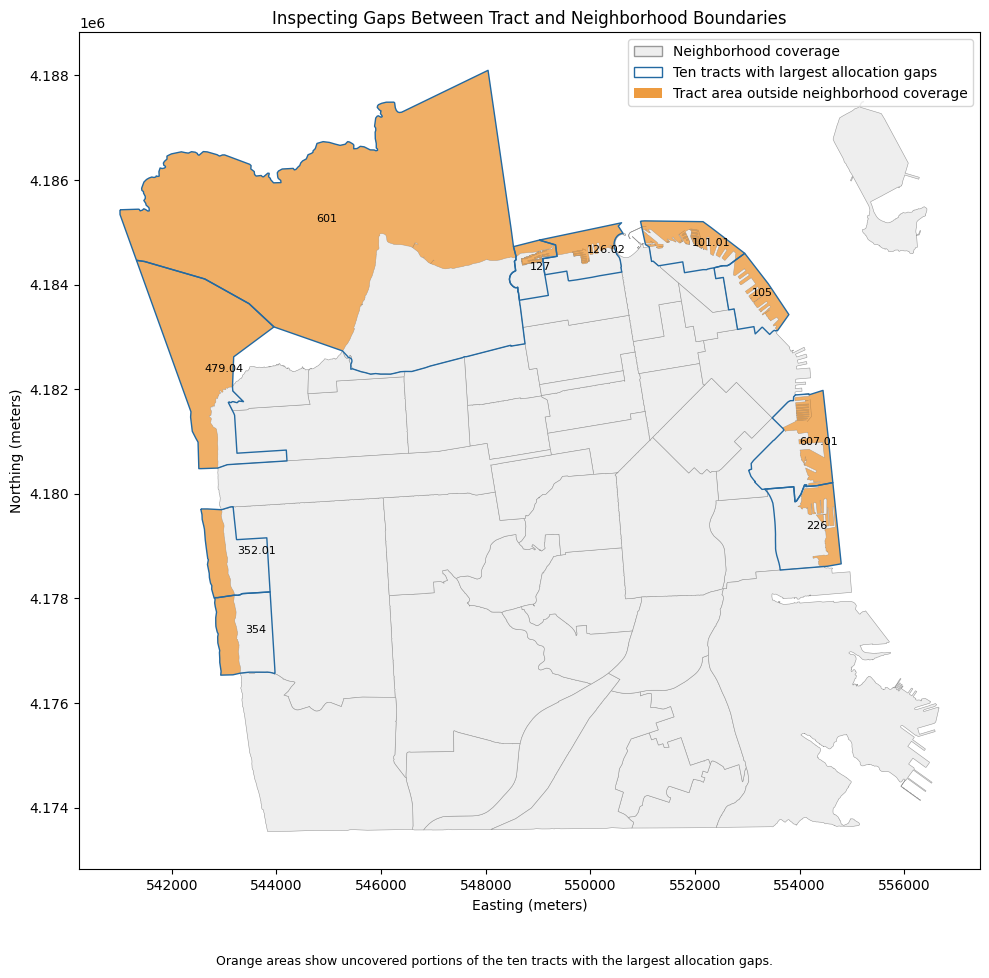

In [21]:
from matplotlib.patches import Patch

# Select the ten tracts with the largest household-allocation gaps.
gap_tracts = tracts_projected.loc[
    tracts_projected["GEOID"].isin(largest_gaps["GEOID"])
].copy()

# Find portions of those tracts outside all neighborhood polygons.
uncovered_parts = gpd.overlay(
    gap_tracts[["GEOID", "geometry"]],
    neighborhoods_projected[["geometry"]],
    how="difference",
    keep_geom_type=True
)

# Compare neighborhood coverage with the original tract footprints.
fig, ax = plt.subplots(figsize=(10, 10))

neighborhoods_projected.plot(
    ax=ax, color="#eeeeee", edgecolor="#999999", linewidth=0.4
)

uncovered_parts.plot(
    ax=ax, color="#ed9b40", edgecolor="none", alpha=0.8
)

gap_tracts.boundary.plot(
    ax=ax, color="#2369a1", linewidth=1
)

# Label the selected tracts using their Census tract names.
for _, row in gap_tracts.iterrows():
    point = row.geometry.representative_point()
    ax.annotate(
        row["NAME"],
        (point.x, point.y),
        fontsize=8
    )

ax.legend(handles=[
    Patch(
        facecolor="#eeeeee", edgecolor="#999999",
        label="Neighborhood coverage"
    ),
    Patch(
        facecolor="none", edgecolor="#2369a1",
        label="Ten tracts with largest allocation gaps"
    ),
    Patch(
        facecolor="#ed9b40",
        label="Tract area outside neighborhood coverage"
    )
])

ax.set_title("Inspecting Gaps Between Tract and Neighborhood Boundaries")
ax.set_xlabel("Easting (meters)")
ax.set_ylabel("Northing (meters)")

fig.text(
    0.5, 0.02,
    "Orange areas show uncovered portions of the ten tracts with the largest allocation gaps.",
    ha="center",
    fontsize=9
)

plt.tight_layout(rect=[0, 0.05, 1, 1])
plt.show()

In [22]:
# Attach Census land and water areas to the ten largest-gap tracts.
water_check = largest_gaps[
    ["GEOID", "NAME", "covered_share"]
].merge(
    tracts_projected[["GEOID", "ALAND", "AWATER"]],
    on="GEOID",
    how="left",
    validate="one_to_one"
)

# Percentage of each tract outside neighborhood coverage.
water_check["uncovered_area_pct"] = (
    100 * (1 - water_check["covered_share"])
)

# Percentage of each tract classified as water by the Census.
water_check["water_area_pct"] = (
    100 * water_check["AWATER"]
    / (water_check["ALAND"] + water_check["AWATER"])
)

display(
    water_check[
        ["GEOID", "NAME", "uncovered_area_pct", "water_area_pct"]
    ].round(2)
)

,GEOID,NAME,uncovered_area_pct,water_area_pct
0,06075060701,607.01,40.28,42.70
1,06075047904,479.04,84.56,84.10
2,06075060100,601,76.88,76.84
3,06075035400,354,35.11,35.11
4,06075010500,105,41.85,42.60
5,06075035201,352.01,40.14,40.14
6,06075012602,126.02,46.41,46.88
7,06075022600,226,29.51,30.32
8,06075012700,127,31.66,36.85
9,06075010101,101.01,48.59,50.32


The initial allocation left approximately 12,095 households unallocated.
A map inspection and comparison with Census water-area totals suggest
that coastal water explains much of the uncovered tract area.

We therefore allocate each tract's households in proportion to its area
covered by neighborhoods. This assumes uncovered portions contain no
households and households are evenly distributed across covered portions.
It preserves tract household totals by construction, but does not locate
residences or remove parks and other nonresidential land.

In [23]:
# Sum the neighborhood-covered area within each tract.
covered_area_per_piece = (
    overlaps.groupby("GEOID")["overlap_area_m2"].transform("sum")
)

# Calculate each piece's share of its tract's covered area.
overlaps["covered_area_share"] = (
    overlaps["overlap_area_m2"]
    / covered_area_per_piece
)

# Allocate households across the covered portions of each tract.
# Preserve estimated_households as the original baseline.
overlaps["estimated_households_adjusted"] = (
    overlaps["households"]
    * overlaps["covered_area_share"]
)

# Compare adjusted household totals with the original Census totals.
adjusted_by_tract = (
    overlaps.groupby("GEOID")["estimated_households_adjusted"].sum()
)

tract_coverage["adjusted_allocated_households"] = (
    tract_coverage["GEOID"]
    .map(adjusted_by_tract)
    .fillna(0)
)

# Check every tract, including the two without neighborhood overlaps.
household_discrepancy = (
    tract_coverage["adjusted_allocated_households"]
    - tract_coverage["households"]
)

print(f"Original Census households: {source_households:,.1f}")
print(f"Original allocation: {allocated_households:,.1f}")
print(
    "Adjusted allocation:",
    f"{overlaps['estimated_households_adjusted'].sum():,.1f}"
)
print(
    "Tracts with household-total discrepancies:",
    household_discrepancy.abs().gt(1e-6).sum()
)

Original Census households: 363,970.0
Original allocation: 351,875.0
Adjusted allocation: 363,970.0
Tracts with household-total discrepancies: 0


In [24]:
def summarize_neighborhood_income(data, household_column):
    """Summarize household-weighted tract incomes by neighborhood."""
    work = data.copy()

    # Retain all allocated households for the coverage calculation.
    work["allocated_households"] = work[household_column]

    # Only households with usable income contribute to income weights.
    work["households_with_income"] = work[household_column].where(
        work["eligible_for_income_weighting"], 0
    )

    work["income_numerator"] = (
        work["median_income"] * work["households_with_income"]
    ).fillna(0)

    # Track the weight contributed by open-ended income estimates.
    work["open_ended_households"] = work["households_with_income"].where(
        work["income_open_ended"], 0
    )

    summary = work.groupby("nhood", as_index=False).agg(
        estimated_households=("allocated_households", "sum"),
        households_with_income=("households_with_income", "sum"),
        income_numerator=("income_numerator", "sum"),
        open_ended_households=("open_ended_households", "sum")
    )

    # Zero denominators become missing rather than producing invalid ratios.
    income_denominator = summary["households_with_income"].where(
        summary["households_with_income"].gt(0)
    )
    total_denominator = summary["estimated_households"].where(
        summary["estimated_households"].gt(0)
    )

    summary["estimated_income"] = (
        summary["income_numerator"] / income_denominator
    )
    summary["income_coverage_pct"] = (
        100 * summary["households_with_income"] / total_denominator
    )
    summary["open_ended_weight_pct"] = (
        100 * summary["open_ended_households"] / income_denominator
    )

    return summary.drop(columns="income_numerator")


# Apply the same calculation to the original and adjusted allocations.
neighborhood_income_original = summarize_neighborhood_income(
    overlaps, "estimated_households"
)

neighborhood_income_adjusted = summarize_neighborhood_income(
    overlaps, "estimated_households_adjusted"
)

print("Neighborhoods summarized:", len(neighborhood_income_adjusted))
print(
    "Neighborhoods without a usable income estimate:",
    neighborhood_income_adjusted["estimated_income"].isna().sum()
)

# Inspect neighborhoods with the lowest income-data coverage first.
display(
    neighborhood_income_adjusted.sort_values("income_coverage_pct")[
        ["nhood", "estimated_households", "estimated_income",
         "income_coverage_pct", "open_ended_weight_pct"]
    ].head(10).round(2)
)

Neighborhoods summarized: 41
Neighborhoods without a usable income estimate: 0


,nhood,estimated_households,estimated_income,income_coverage_pct,open_ended_weight_pct
35,Tenderloin,18120.35,53338.05,79.51,0.00
13,Lakeshore,4867.72,70924.54,86.89,0.00
33,South of Market,13799.09,112576.65,88.86,0.00
0,Bayview Hunters Point,12275.31,95662.16,98.06,0.00
5,Financial District/South Beach,14227.96,183869.83,99.96,21.75
40,Western Addition,11237.05,104538.73,99.97,0.00
1,Bernal Heights,9167.86,183079.24,100.00,0.00
34,Sunset/Parkside,27113.99,149321.83,100.00,0.00
28,Potrero Hill,7631.14,223319.56,100.00,36.97
4,Excelsior,11109.15,117684.79,100.00,0.00


In [25]:
# Match each neighborhood's original and adjusted income estimates.
income_comparison = (
    neighborhood_income_original[
        ["nhood", "estimated_income"]
    ]
    .rename(columns={"estimated_income": "original_income"})
    .merge(
        neighborhood_income_adjusted[
            ["nhood", "estimated_income",
             "income_coverage_pct", "open_ended_weight_pct"]
        ].rename(columns={"estimated_income": "adjusted_income"}),
        on="nhood",
        how="inner",
        validate="one_to_one"
    )
)

# Measure the change in dollars and as a percentage of the original.
income_comparison["change_dollars"] = (
    income_comparison["adjusted_income"]
    - income_comparison["original_income"]
)

income_comparison["change_pct"] = (
    100 * income_comparison["change_dollars"]
    / income_comparison["original_income"]
)

# Absolute changes measure the size of the difference in either direction.
income_comparison["absolute_change_pct"] = (
    income_comparison["change_pct"].abs()
)

print(
    "Median absolute percentage change:",
    f"{income_comparison['absolute_change_pct'].median():.2f}%"
)
print(
    "Largest absolute percentage change:",
    f"{income_comparison['absolute_change_pct'].max():.2f}%"
)

# Inspect the ten neighborhoods most affected by the adjustment.
display(
    income_comparison.sort_values(
        "absolute_change_pct", ascending=False
    )[
        ["nhood", "original_income", "adjusted_income",
         "change_dollars", "change_pct", "income_coverage_pct"]
    ].head(10).round(2)
)

Median absolute percentage change: 0.00%
Largest absolute percentage change: 5.52%


,nhood,original_income,adjusted_income,change_dollars,change_pct,income_coverage_pct
14,Lincoln Park,136389.09,143918.34,7529.25,5.52,100.00
19,Mission Bay,190146.87,197815.55,7668.68,4.03,100.00
22,North Beach,129209.92,125288.27,-3921.66,-3.04,100.00
0,Bayview Hunters Point,94034.57,95662.16,1627.59,1.73,98.06
5,Financial District/South Beach,186961.51,183869.83,-3091.68,-1.65,99.96
25,Outer Richmond,137176.22,135233.19,-1943.03,-1.42,100.00
16,Marina,212547.68,215421.05,2873.38,1.35,100.00
31,Russian Hill,157063.68,158093.81,1030.13,0.66,100.00
13,Lakeshore,70636.27,70924.54,288.27,0.41,86.89
7,Golden Gate Park,124631.05,124146.67,-484.38,-0.39,100.00


## Income groups and case selection

We divide all 41 neighborhoods into three relative income groups using
the adjusted income estimates. These groups describe neighborhood
rankings within San Francisco, not official income or affordability categories.

We compare group assignments under both allocation methods, then inspect
an initial six-neighborhood selection before applying a minimum estimated
household requirement for case selection.

In [26]:
def assign_relative_income_bands(summary):
    """Divide neighborhood income estimates into three relative groups."""
    table = summary.sort_values(
        ["estimated_income", "nhood"]
    ).reset_index(drop=True).copy()

    table["income_band"], cutoffs = pd.qcut(
        table["estimated_income"],
        q=3,
        labels=["Lower", "Middle", "Higher"],
        retbins=True
    )

    return table, cutoffs


# Classify all 41 neighborhoods under each allocation method.
income_table, income_cutoffs = assign_relative_income_bands(
    neighborhood_income_adjusted
)

income_table_original, original_cutoffs = assign_relative_income_bands(
    neighborhood_income_original
)

# Compare group assignments using neighborhood names.
group_comparison = (
    income_table_original[["nhood", "income_band"]]
    .rename(columns={"income_band": "original_band"})
    .merge(
        income_table[["nhood", "income_band"]].rename(
            columns={"income_band": "adjusted_band"}
        ),
        on="nhood",
        validate="one_to_one"
    )
)

changed_group = (
    group_comparison["original_band"]
    != group_comparison["adjusted_band"]
)

print("Neighborhoods per adjusted income group:")
print(
    income_table["income_band"]
    .value_counts()
    .reindex(["Lower", "Middle", "Higher"])
)

print(f"\nLower/Middle dividing value: ${income_cutoffs[1]:,.2f}")
print(f"Middle/Higher dividing value: ${income_cutoffs[2]:,.2f}")
print("\nNeighborhoods changing income group:", changed_group.sum())

Neighborhoods per adjusted income group:
income_band
Lower     14
Middle    13
Higher    14
Name: count, dtype: int64

Lower/Middle dividing value: $127,117.17
Middle/Higher dividing value: $175,774.75

Neighborhoods changing income group: 0


In [27]:
# Calculate group medians using all 41 neighborhoods.
selection_candidates = income_table.copy()

selection_candidates["band_median_income"] = (
    selection_candidates.groupby(
        "income_band", observed=True
    )["estimated_income"].transform("median")
)

# Measure each neighborhood's distance from its group's median.
selection_candidates["distance_from_band_median"] = (
    selection_candidates["estimated_income"]
    - selection_candidates["band_median_income"]
).abs()

# Select the nearest two in each group without a household minimum.
# Alphabetical order provides a reproducible tie-break.
initial_selected_neighborhoods = (
    selection_candidates.sort_values(
        ["income_band", "distance_from_band_median", "nhood"]
    )
    .groupby("income_band", observed=True)
    .head(2)
    .reset_index(drop=True)
)

print("Initially selected neighborhoods per group:")
print(
    initial_selected_neighborhoods["income_band"]
    .value_counts()
    .reindex(["Lower", "Middle", "Higher"])
)

# Inspect household totals, income coverage, and open-ended income weights.
display(
    initial_selected_neighborhoods[
        ["nhood", "income_band", "estimated_income",
         "band_median_income", "estimated_households",
         "income_coverage_pct", "open_ended_weight_pct"]
    ].round(2)
)

Initially selected neighborhoods per group:
income_band
Lower     2
Middle    2
Higher    2
Name: count, dtype: int64


,nhood,income_band,estimated_income,band_median_income,estimated_households,income_coverage_pct,open_ended_weight_pct
0,Bayview Hunters Point,Lower,95662.16,95753.37,12275.31,98.06,0.00
1,Japantown,Lower,95844.59,95753.37,2211.34,100.00,0.00
2,Mission,Middle,146512.40,146512.40,23697.25,100.00,0.00
3,Lincoln Park,Middle,143918.34,146512.40,79.48,100.00,18.43
4,Mission Bay,Higher,197815.55,198117.45,7835.91,100.00,0.00
5,Haight Ashbury,Higher,198419.36,198117.45,8128.06,100.00,0.00


The initial selection included Lincoln Park, with approximately 79
estimated households. To focus our accessibility comparison on
neighborhoods with a substantial residential base, we require at least
1,000 estimated households for case selection.

This is a practical selection rule, not a statistical reliability
threshold. All 41 neighborhoods remain in the income classification,
and group medians remain unchanged. We select the two eligible
neighborhoods closest to each group's original median income.

In [28]:
# Apply a household minimum only to case selection.
MIN_ESTIMATED_HOUSEHOLDS = 1000

eligible_mask = (
    selection_candidates["estimated_households"]
    >= MIN_ESTIMATED_HOUSEHOLDS
)

eligible_candidates = selection_candidates.loc[eligible_mask].copy()
excluded_candidates = selection_candidates.loc[~eligible_mask].copy()

# Document every neighborhood excluded by this rule.
print("Neighborhoods excluded from case selection:")
display(
    excluded_candidates[
        ["nhood", "income_band", "estimated_households"]
    ].round(2)
)

# Use the group medians already calculated from all 41 neighborhoods.
# Alphabetical order provides a reproducible tie-break.
selected_neighborhoods = (
    eligible_candidates.sort_values(
        ["income_band", "distance_from_band_median", "nhood"]
    )
    .groupby("income_band", observed=True)
    .head(2)
    .reset_index(drop=True)
)

print("Selected neighborhoods per group:")
print(
    selected_neighborhoods["income_band"]
    .value_counts()
    .reindex(["Lower", "Middle", "Higher"])
)

display(
    selected_neighborhoods[
        ["nhood", "income_band", "estimated_income",
         "band_median_income", "estimated_households",
         "income_coverage_pct", "open_ended_weight_pct"]
    ].round(2)
)

Neighborhoods excluded from case selection:


,nhood,income_band,estimated_households
2,McLaren Park,Lower,378.35
5,Treasure Island,Lower,616.00
12,Golden Gate Park,Lower,85.18
19,Lincoln Park,Middle,79.48
40,Seacliff,Higher,930.20


Selected neighborhoods per group:
income_band
Lower     2
Middle    2
Higher    2
Name: count, dtype: int64


,nhood,income_band,estimated_income,band_median_income,estimated_households,income_coverage_pct,open_ended_weight_pct
0,Bayview Hunters Point,Lower,95662.16,95753.37,12275.31,98.06,0.0
1,Japantown,Lower,95844.59,95753.37,2211.34,100.00,0.0
2,Mission,Middle,146512.40,146512.40,23697.25,100.00,0.0
3,Sunset/Parkside,Middle,149321.83,146512.40,27113.99,100.00,0.0
4,Mission Bay,Higher,197815.55,198117.45,7835.91,100.00,0.0
5,Haight Ashbury,Higher,198419.36,198117.45,8128.06,100.00,0.0


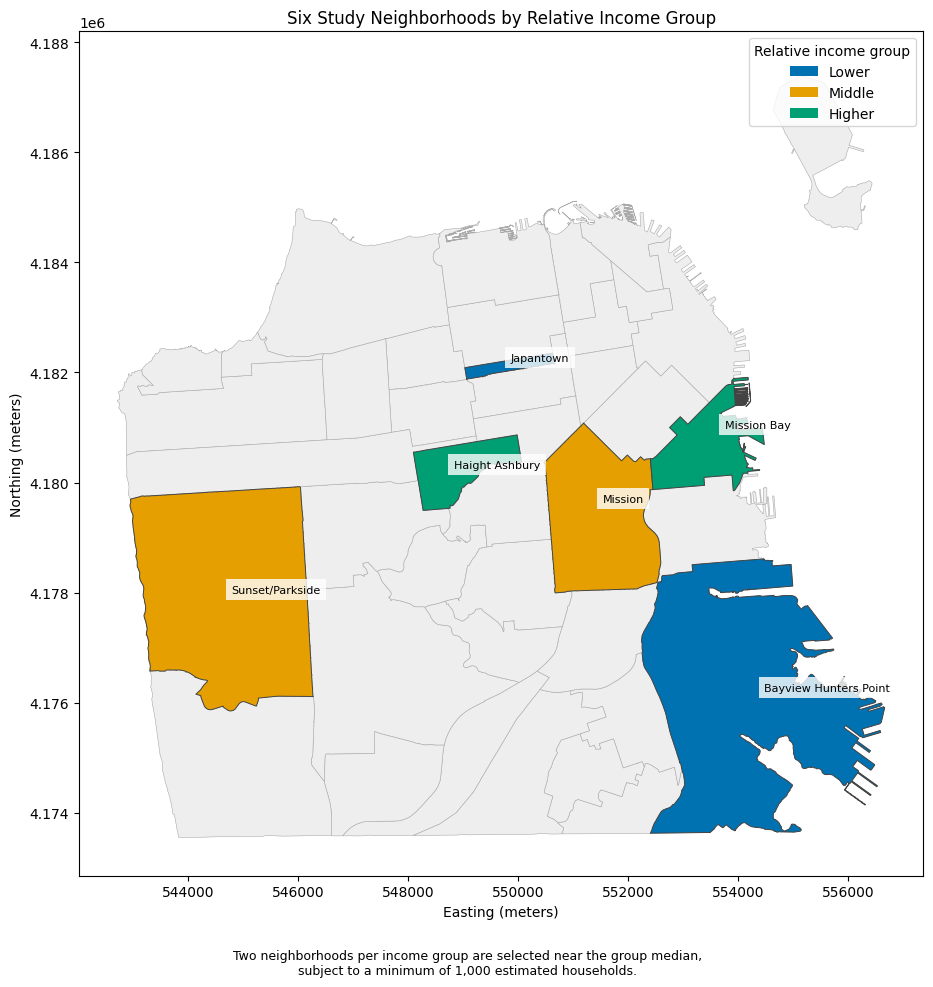

Study neighborhoods: 6
Saved: outputs/figures/selected_neighborhoods_income_groups.png


In [29]:
from matplotlib.patches import Patch

# Attach the selected neighborhoods' income information to their boundaries.
study_neighborhoods = neighborhoods_projected[
    ["nhood", "geometry"]
].merge(
    selected_neighborhoods,
    on="nhood",
    how="inner",
    validate="one_to_one"
)

# Use these colors consistently in subsequent maps and charts.
income_colors = {
    "Lower": "#0072B2",
    "Middle": "#E69F00",
    "Higher": "#009E73"
}

fig, ax = plt.subplots(figsize=(10, 10))

# Show all neighborhoods as geographic context.
neighborhoods_projected.plot(
    ax=ax,
    color="#eeeeee",
    edgecolor="#aaaaaa",
    linewidth=0.4
)

# Highlight the six selected neighborhoods by relative income group.
for band, color in income_colors.items():
    study_neighborhoods.loc[
        study_neighborhoods["income_band"].eq(band)
    ].plot(
        ax=ax,
        color=color,
        edgecolor="#444444",
        linewidth=0.7
    )

# Place labels inside each neighborhood where possible.
for _, row in study_neighborhoods.iterrows():
    point = row.geometry.representative_point()
    ax.annotate(
        row["nhood"],
        xy=(point.x, point.y),
        xytext=(4, 4),
        textcoords="offset points",
        fontsize=8,
        bbox=dict(facecolor="white", alpha=0.8, edgecolor="none")
    )

ax.legend(
    handles=[
        Patch(facecolor=color, label=band)
        for band, color in income_colors.items()
    ],
    title="Relative income group"
)

ax.set_title("Six Study Neighborhoods by Relative Income Group")
ax.set_xlabel("Easting (meters)")
ax.set_ylabel("Northing (meters)")

fig.text(
    0.5, 0.02,
    "Two neighborhoods per income group are selected near the group median,\n"
    "subject to a minimum of 1,000 estimated households.",
    ha="center",
    fontsize=9
)

plt.tight_layout(rect=[0, 0.06, 1, 1])

# Save a report-ready copy using a relative output path.
figures_dir = Path("outputs/figures")
figures_dir.mkdir(parents=True, exist_ok=True)

map_file = figures_dir / "selected_neighborhoods_income_groups.png"
fig.savefig(map_file, dpi=300, bbox_inches="tight")

plt.show()
print("Study neighborhoods:", len(study_neighborhoods))
print("Saved:", map_file)

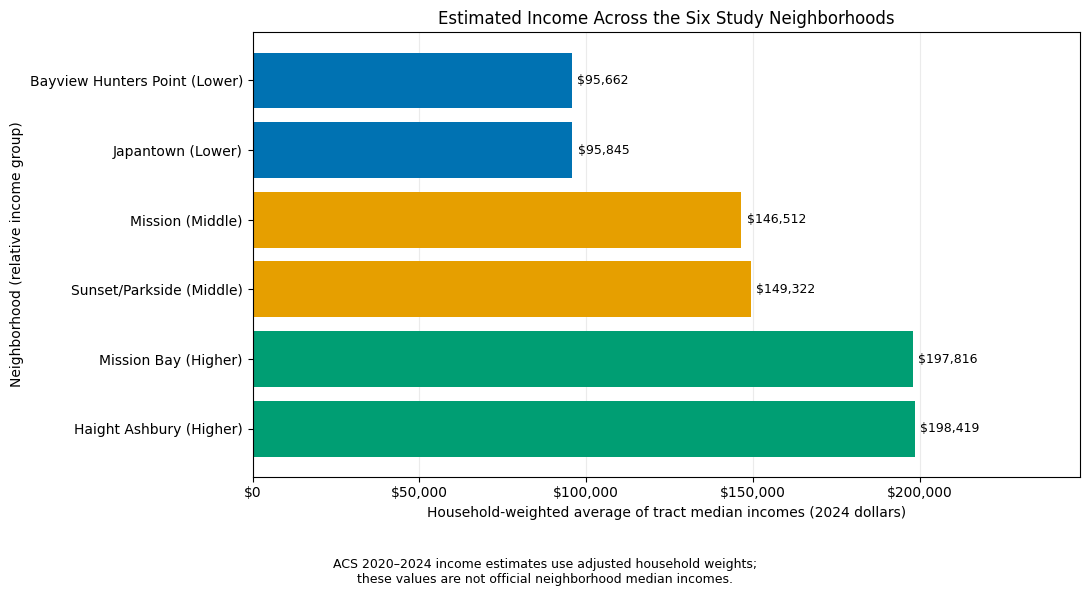

Saved: outputs/figures/selected_neighborhoods_income.png


In [30]:
from matplotlib.ticker import StrMethodFormatter

# Order the selected neighborhoods from lowest to highest income.
chart_data = selected_neighborhoods.sort_values(
    "estimated_income"
).copy()

labels = [
    f"{name} ({band})"
    for name, band in zip(chart_data["nhood"], chart_data["income_band"])
]
colors = [
    income_colors[band]
    for band in chart_data["income_band"]
]

fig, ax = plt.subplots(figsize=(11, 6))

bars = ax.barh(
    labels,
    chart_data["estimated_income"],
    color=colors
)
ax.invert_yaxis()

# Label bars with estimated dollar values.
ax.bar_label(
    bars,
    labels=[
        f"${value:,.0f}"
        for value in chart_data["estimated_income"]
    ],
    padding=4,
    fontsize=9
)

# Leave space for labels and format the axis in dollars.
ax.set_xlim(0, chart_data["estimated_income"].max() * 1.25)
ax.xaxis.set_major_formatter(StrMethodFormatter("${x:,.0f}"))

ax.set_title("Estimated Income Across the Six Study Neighborhoods")
ax.set_xlabel(
    "Household-weighted average of tract median incomes (2024 dollars)"
)
ax.set_ylabel("Neighborhood (relative income group)")
ax.set_axisbelow(True)
ax.grid(axis="x", alpha=0.25)

fig.text(
    0.5, 0.02,
    "ACS 2020–2024 income estimates use adjusted household weights;\n"
    "these values are not official neighborhood median incomes.",
    ha="center",
    fontsize=9
)

plt.tight_layout(rect=[0, 0.10, 1, 1])

chart_file = figures_dir / "selected_neighborhoods_income.png"
fig.savefig(chart_file, dpi=300, bbox_inches="tight")

plt.show()
print("Saved:", chart_file)

In [31]:
def save_table(table, destination):
    """Save a table without its pandas index."""
    destination = Path(destination)
    destination.parent.mkdir(parents=True, exist_ok=True)
    table.to_csv(destination, index=False)
    print(f"Saved {destination} ({len(table)} rows)")


# Save results and checks using relative project paths.
tables_dir = Path("outputs/tables")

tables_to_save = {
    "neighborhood_income_all_41.csv": income_table,
    "selected_neighborhoods.csv": selected_neighborhoods,
    "initial_selected_neighborhoods.csv": initial_selected_neighborhoods,
    "excluded_selection_candidates.csv": excluded_candidates,
    "income_allocation_comparison.csv": income_comparison,
    "acs_cleaning_log.csv": acs_cleaning_log,
    "tract_coverage_check.csv": tract_coverage
}

for filename, table in tables_to_save.items():
    save_table(table, tables_dir / filename)

# Keep the cleaned tract-level Census data separate from the raw source.
save_table(
    income_clean,
    Path("data/processed/acs_2024_sf_tracts_clean.csv")
)

Saved outputs/tables/neighborhood_income_all_41.csv (41 rows)
Saved outputs/tables/selected_neighborhoods.csv (6 rows)
Saved outputs/tables/initial_selected_neighborhoods.csv (6 rows)
Saved outputs/tables/excluded_selection_candidates.csv (5 rows)
Saved outputs/tables/income_allocation_comparison.csv (41 rows)
Saved outputs/tables/acs_cleaning_log.csv (4 rows)
Saved outputs/tables/tract_coverage_check.csv (244 rows)
Saved data/processed/acs_2024_sf_tracts_clean.csv (244 rows)


## Business destinations and opening hours

We will collect OpenStreetMap destinations in four categories:
grocery/convenience, pharmacy/health, food/drink, and general retail.
We include a half-mile buffer around each study neighborhood to capture
nearby destinations beyond its boundary.

We will inspect destination records and opening-hours completeness,
keeping missing hours classified as unknown. The buffer defines an
initial data collection area, not a 15-minute travel area; its extent
must be checked before drawing accessibility conclusions.

In [32]:
# Create search areas from the six selected neighborhood boundaries.
business_search_areas = study_neighborhoods[
    ["nhood", "income_band", "geometry"]
].copy()

# Buffer in the projected CRS, whose units are meters.
BUSINESS_BUFFER_METERS = 0.5 * 1609.344

business_search_areas["geometry"] = (
    business_search_areas.geometry.buffer(BUSINESS_BUFFER_METERS)
)

# Merge overlapping buffers into one combined query geometry.
combined_search_area = business_search_areas.geometry.union_all()

# OpenStreetMap queries require longitude/latitude coordinates.
business_query_polygon = (
    gpd.GeoSeries(
        [combined_search_area],
        crs=business_search_areas.crs
    )
    .to_crs(epsg=4326)
    .iloc[0]
)

print("Neighborhood search areas:", len(business_search_areas))
print("Buffer distance:", BUSINESS_BUFFER_METERS, "meters")
print("Combined query geometry:", business_query_polygon.geom_type)

display(business_search_areas[["nhood", "income_band"]])

Neighborhood search areas: 6
Buffer distance: 804.672 meters
Combined query geometry: MultiPolygon


,nhood,income_band
0,Sunset/Parkside,Middle
1,Mission Bay,Higher
2,Mission,Middle
3,Japantown,Lower
4,Haight Ashbury,Higher
5,Bayview Hunters Point,Lower
